# RMIT_SGS_Sigma69_C1 — DistilBERT multilingual + QLoRA (Colab)

Notebook độc lập cho Challenge 1: fine-tune **distilbert/distilbert-base-multilingual-cased** bằng **4-bit NF4 + LoRA** và phân loại **BENIGN / JAILBREAK / PROMPT_INJECTION**.

**Cách dùng**
1. Upload file notebook này vào Google Colab.
2. Chọn **Runtime → Change runtime type → GPU** (T4 dùng được).
3. Chạy lần lượt các cell. Tại cell dữ liệu, upload **train.csv**, **test.csv**, **sample_submission.csv** hoặc một file ZIP chứa cả ba.
4. Cell training sẽ fine-tune; các cell cuối lưu adapter, báo cáo và **submission.csv** để tải xuống.

Mặc định: 3 epoch, 512 token, LoRA rank 16, effective batch size 32, validation 10%, weighted cross entropy. Mô hình được chọn theo validation Macro F1; test chỉ dùng để dự đoán.

Notebook được tạo để bạn chạy; **chưa được thực thi hoặc đo chất lượng trên GPU**. Không tự nộp bài lên Kaggle. Kết quả huấn luyện trên Colab vẫn cần được đưa vào quy trình Kaggle của đội.


## 1. Cài dependencies

Chạy trên runtime mới. Cell này giữ PyTorch CUDA có sẵn của Colab và khóa phiên bản các thư viện QLoRA. Nếu Colab báo cần restart sau khi cài, chọn **Restart session**, rồi chạy lại từ đầu. Không đổi tên biến model sang backbone khác.


In [1]:
import os
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

PINS = {
    "transformers": "4.57.6",
    "peft": "0.17.1",
    "accelerate": "1.10.1",
    "bitsandbytes": "0.48.1",
}
loaded_conflicts = []
for package, wanted in PINS.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    if package in sys.modules and installed != wanted:
        loaded_conflicts.append(package)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet",
    *[f"{name}=={release}" for name, release in PINS.items()],
    "huggingface-hub>=0.34,<1",
    "scikit-learn>=1.5,<2", "pandas>=2.2,<3",
    "matplotlib>=3.8,<4", "safetensors>=0.4.3",
])
if loaded_conflicts:
    raise RuntimeError(
        "Da doi thu vien dang duoc import: " + ", ".join(loaded_conflicts)
        + ". Chon Runtime > Restart session, sau do chay lai tu dau."
    )
print("Dependencies ready. PyTorch CUDA cua Colab duoc giu nguyen.")


Dependencies ready. PyTorch CUDA cua Colab duoc giu nguyen.


## 2. Cấu hình

Giữ **DATA_MODE = "upload"** để chọn CSV/ZIP từ máy. Nếu dữ liệu đã ở Colab, chọn **"path"** và sửa DATA_DIR. Muốn dùng Google Drive, bật MOUNT_DRIVE và đặt DATA_DIR hoặc OUTPUT_ROOT dưới thư mục Drive.

TRAIN_BATCH_SIZE × GRAD_ACCUM_STEPS = effective batch size. Nếu hết VRAM, giảm batch từ 8 xuống 4 và tăng accumulation từ 4 lên 8. LONG_TEXT_MODE có thể đổi từ **"head"** sang **"head_tail"** cho một thí nghiệm riêng.


In [2]:
# Chinh cac gia tri o cell nay truoc khi chay tiep.
DATA_MODE = "upload"                     # "upload" hoac "path"
DATA_DIR = "/content/rmit-hackathon-2026"
MOUNT_DRIVE = False
OUTPUT_ROOT = "/content/rmit_c1_runs"      # Co the doi sang /content/drive/MyDrive/...
MODEL_SOURCE = "distilbert/distilbert-base-multilingual-cased"
MODEL_REVISION = "main"                   # Hoac commit hash cua model
RUN_NAME = "distilmbert_qlora"

SEED = 42
VAL_SIZE = 0.10
MAX_LENGTH = 512
LONG_TEXT_MODE = "head"                   # "head" hoac "head_tail"
EPOCHS = 3
LEARNING_RATE = 2e-4
TRAIN_BATCH_SIZE = 8
EVAL_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
EARLY_STOPPING_PATIENCE = 2
USE_CLASS_WEIGHTS = True
GRADIENT_CHECKPOINTING = True

LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
LORA_TARGETS = ["q_lin", "v_lin"]
HEAD_MODULES = ["pre_classifier", "classifier"]
LABELS = ["BENIGN", "JAILBREAK", "PROMPT_INJECTION"]
LABEL2ID = {label: index for index, label in enumerate(LABELS)}
ID2LABEL = {index: label for label, index in LABEL2ID.items()}
LANGUAGES = ["pt", "fr", "it", "en"]

# Notebook nay dung mot GPU. Thiet lap truoc khi import torch.
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

assert DATA_MODE in {"upload", "path"}
assert LONG_TEXT_MODE in {"head", "head_tail"}
assert 0 < VAL_SIZE < 1
assert 8 <= MAX_LENGTH <= 512 and MAX_LENGTH % 8 == 0
assert TRAIN_BATCH_SIZE > 0 and GRAD_ACCUM_STEPS > 0
assert EPOCHS >= 1
print("Effective batch size:", TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS)


Effective batch size: 32


In [3]:
import gc
import io
import json
import hashlib
import shutil
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import bitsandbytes as bnb
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)
from transformers import (
    AutoConfig, AutoTokenizer, AutoModelForSequenceClassification,
    BitsAndBytesConfig, DataCollatorWithPadding, Trainer,
    TrainingArguments, EarlyStoppingCallback, set_seed,
)
from peft import LoraConfig, TaskType, get_peft_model, prepare_model_for_kbit_training
from IPython.display import display, FileLink

if not torch.cuda.is_available():
    raise RuntimeError("Can GPU CUDA: Runtime > Change runtime type > GPU, roi chay lai.")
if torch.cuda.device_count() != 1:
    raise RuntimeError("Notebook yeu cau mot GPU. Restart runtime de CUDA_VISIBLE_DEVICES co hieu luc.")

set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
USE_BF16 = torch.cuda.is_bf16_supported()
COMPUTE_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
PACKAGE_VERSIONS = {
    name: version(name)
    for name in ["torch", "transformers", "peft", "accelerate", "bitsandbytes",
                 "huggingface-hub", "numpy", "pandas", "scikit-learn", "safetensors"]
}
for package, wanted in PINS.items():
    if PACKAGE_VERSIONS[package] != wanted:
        raise RuntimeError(f"Sai version {package}; restart runtime va chay lai cell cai dat.")

DATA_PATH = Path(DATA_DIR)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = Path(OUTPUT_ROOT) / f"{RUN_NAME}_{RUN_ID}"
ARTIFACT_DIR = RUN_DIR / "artifacts"
ADAPTER_DIR = ARTIFACT_DIR / "adapter"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=False)

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
print("Compute dtype:", COMPUTE_DTYPE)
print("Output:", RUN_DIR)
display(pd.DataFrame(PACKAGE_VERSIONS.items(), columns=["package", "version"]))


GPU: Tesla T4
VRAM (GiB): 14.6
Compute dtype: torch.bfloat16
Output: /content/rmit_c1_runs/distilmbert_qlora_20261022T041806_813715Z


,package,version
0,torch,2.11.0+cu130
1,transformers,4.57.6
2,peft,0.17.1
3,accelerate,1.10.1
4,bitsandbytes,0.48.1
5,huggingface-hub,0.36.2
6,numpy,2.1.3
7,pandas,2.2.3
8,scikit-learn,1.6.1
9,safetensors,0.8.0


## 3. Upload dữ liệu

Chọn cả ba CSV trong một lần hoặc upload ZIP từ Kaggle. Nếu dùng ZIP, notebook chỉ lấy ba CSV có tên đúng, kể cả khi chúng nằm trong thư mục con. Không cần Kaggle token và không tải dữ liệu từ GitHub.


In [6]:
EXPECTED_FILES = {"train.csv", "test.csv", "sample_submission.csv"}

if DATA_MODE == "upload":
    from google.colab import files
    uploaded = files.upload()
    selected = {}

    def add_csv(name, payload):
        if name in selected:
            raise ValueError(f"Trung file {name} trong lan upload. Chi chon mot ban moi file.")
        selected[name] = payload

    for upload_name, payload in uploaded.items():
        filename = Path(upload_name).name
        if filename in EXPECTED_FILES:
            add_csv(filename, payload)
        elif filename.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                for member in archive.infolist():
                    name = Path(member.filename).name
                    if not member.is_dir() and name in EXPECTED_FILES:
                        add_csv(name, archive.read(member))

    missing = EXPECTED_FILES - set(selected)
    if missing:
        raise ValueError(f"Upload thieu {sorted(missing)}. Chay lai cell va chon ca ba CSV/ZIP.")
    DATA_PATH.mkdir(parents=True, exist_ok=True)
    for name, payload in selected.items():
        (DATA_PATH / name).write_bytes(payload)
    del uploaded, selected

missing = [name for name in EXPECTED_FILES if not (DATA_PATH / name).is_file()]
if missing:
    raise FileNotFoundError(f"Khong tim thay {missing} trong {DATA_PATH}. Kiem tra DATA_DIR.")
print("Data directory:", DATA_PATH)


Saving rmit-hackathon-2026.zip to rmit-hackathon-2026 (1).zip
Data directory: /content/rmit-hackathon-2026


In [7]:
def load_csv(name):
    # Giu nguyen text va ID, khong bien chuoi "NA" thanh gia tri thieu.
    return pd.read_csv(DATA_PATH / name, dtype=str, keep_default_na=False, encoding="utf-8-sig")

train_df = load_csv("train.csv")
test_df = load_csv("test.csv")
sample_df = load_csv("sample_submission.csv")

def validate_frame(frame, name, columns, expected_rows):
    if list(frame.columns) != columns:
        raise ValueError(f"{name}: can cot {columns}; nhan duoc {list(frame.columns)}.")
    if len(frame) != expected_rows:
        raise ValueError(f"{name}: can {expected_rows} dong; nhan duoc {len(frame)}.")
    if frame["id"].isna().any() or frame["id"].str.strip().eq("").any() or not frame["id"].is_unique:
        raise ValueError(f"{name}: ID rong hoac trung.")
    for column in ["text", "language"]:
        if column in frame and (
            frame[column].isna().any() or frame[column].str.strip().eq("").any()
        ):
            raise ValueError(f"{name}: {column} rong.")
    if "language" in frame and not set(frame["language"]).issubset(LANGUAGES):
        raise ValueError(f"{name}: language ngoai mien {LANGUAGES}.")

validate_frame(train_df, "train.csv", ["id", "text", "language", "label"], 14000)
validate_frame(test_df, "test.csv", ["id", "text", "language"], 6000)
validate_frame(sample_df, "sample_submission.csv", ["id", "label"], 6000)
if set(train_df["label"]) != set(LABELS):
    raise ValueError("Train phai chua du ba nhan chinh xac.")
if set(sample_df["id"]) != set(test_df["id"]):
    raise ValueError("ID sample_submission khong khop test.")
if train_df["text"].duplicated().any():
    raise ValueError("Train co text trung; can group-aware split de tranh leakage.")

train_df["label_id"] = train_df["label"].map(LABEL2ID).astype("int64")
DATA_HASHES = {
    name: hashlib.sha256((DATA_PATH / name).read_bytes()).hexdigest()
    for name in sorted(EXPECTED_FILES)
}
display(pd.crosstab(train_df["language"], train_df["label"]).reindex(columns=LABELS))
display(train_df["text"].str.len().describe().rename("text_characters").to_frame())
print("Train:", len(train_df), "| Test:", len(test_df))
print("Sample labels chi la placeholder; khong dung lam ground truth.")


label,BENIGN,JAILBREAK,PROMPT_INJECTION
language,,,
en,868,434,98
fr,2170,1085,245
it,1736,868,196
pt,3906,1953,441


,text_characters
count,14000.000000
mean,507.512286
std,685.185818
min,10.000000
25%,80.000000
50%,294.000000
75%,735.000000
max,18550.000000


Train: 14000 | Test: 6000
Sample labels chi la placeholder; khong dung lam ground truth.


## 4. Tách validation cố định

Dùng 90% train để học và 10% để đánh giá (12.600 / 1.400 dòng với cấu hình mặc định). Chia theo **language + label**; class weights chỉ tính từ phần huấn luyện. Không sử dụng test labels hoặc sample labels để chọn model.


In [8]:
strata = train_df["language"] + "::" + train_df["label"]
smallest_group = int(strata.value_counts().min())
if smallest_group < 2:
    raise ValueError("Nhom language/label qua nho; can xem lai cach split.")

fit_df, valid_df = train_test_split(
    train_df, test_size=VAL_SIZE, random_state=SEED, stratify=strata,
)
fit_df = fit_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
assert set(fit_df["id"]).isdisjoint(set(valid_df["id"]))
assert set(fit_df["text"]).isdisjoint(set(valid_df["text"]))
assert set(fit_df["id"]) | set(valid_df["id"]) == set(train_df["id"])

split_manifest = pd.concat([
    fit_df[["id", "language", "label"]].assign(split="train"),
    valid_df[["id", "language", "label"]].assign(split="validation"),
], ignore_index=True)
split_manifest.to_csv(ARTIFACT_DIR / "split.csv", index=False)

class_counts = np.bincount(fit_df["label_id"].to_numpy(), minlength=len(LABELS))
assert (class_counts > 0).all()
weight_values = len(fit_df) / (len(LABELS) * class_counts) if USE_CLASS_WEIGHTS else np.ones(len(LABELS))
class_weights = torch.tensor(weight_values, dtype=torch.float32)
print("Training:", len(fit_df), "| Validation:", len(valid_df))
display(pd.DataFrame({"label": LABELS, "train_count": class_counts, "weight": weight_values}))


Training: 12600 | Validation: 1400


,label,train_count,weight
0,BENIGN,7811,0.537703
1,JAILBREAK,3907,1.074994
2,PROMPT_INJECTION,882,4.761905


## 5. Tokenizer và prompt dài

Dùng tokenizer đi kèm DistilBERT, giữ nguyên chữ hoa/thường. Chế độ **head_tail** ghép token đầu và cuối; tổng độ dài đã tính cả token đặc biệt. **language** được giữ để stratify và đánh giá, không ghép thêm vào prompt trong baseline.


In [9]:
base_config = AutoConfig.from_pretrained(
    MODEL_SOURCE, revision=MODEL_REVISION, trust_remote_code=False,
)
if base_config.model_type != "distilbert":
    raise ValueError("MODEL_SOURCE phai la DistilBERT multilingual da chon.")
if MAX_LENGTH > base_config.max_position_embeddings:
    raise ValueError("MAX_LENGTH vuot gioi han position embeddings.")
RESOLVED_MODEL_REVISION = getattr(base_config, "_commit_hash", None)
LOAD_KWARGS = {
    "revision": RESOLVED_MODEL_REVISION or MODEL_REVISION,
    "trust_remote_code": False,
}
tokenizer = AutoTokenizer.from_pretrained(MODEL_SOURCE, use_fast=True, **LOAD_KWARGS)

def encode_texts(texts):
    if LONG_TEXT_MODE == "head":
        return dict(tokenizer(
            texts, truncation=True, max_length=MAX_LENGTH,
            padding=False, return_token_type_ids=False,
        ))
    raw_ids = tokenizer(texts, add_special_tokens=False, truncation=False)["input_ids"]
    budget = MAX_LENGTH - tokenizer.num_special_tokens_to_add(pair=False)
    head_count = (budget + 1) // 2
    tail_count = budget - head_count
    final_ids = []
    for token_ids in raw_ids:
        if len(token_ids) > budget:
            token_ids = token_ids[:head_count] + token_ids[-tail_count:]
        token_ids = tokenizer.build_inputs_with_special_tokens(token_ids)
        assert len(token_ids) <= MAX_LENGTH
        final_ids.append(token_ids)
    return {"input_ids": final_ids, "attention_mask": [[1] * len(ids) for ids in final_ids]}

class PromptDataset(Dataset):
    def __init__(self, frame, labelled):
        self.features = {"input_ids": [], "attention_mask": []}
        self.labels = frame["label_id"].tolist() if labelled else None
        for start in range(0, len(frame), 256):
            encoded = encode_texts(frame["text"].iloc[start:start + 256].tolist())
            for key in self.features:
                self.features[key].extend(encoded[key])

    def __len__(self):
        return len(self.features["input_ids"])

    def __getitem__(self, index):
        item = {key: values[index] for key, values in self.features.items()}
        if self.labels is not None:
            item["labels"] = int(self.labels[index])
        return item

train_dataset = PromptDataset(fit_df, labelled=True)
valid_dataset = PromptDataset(valid_df, labelled=True)
test_dataset = PromptDataset(test_df, labelled=False)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
print("Datasets:", len(train_dataset), len(valid_dataset), len(test_dataset))
print("Model revision:", RESOLVED_MODEL_REVISION or MODEL_REVISION)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Datasets: 12600 1400 6000
Model revision: 45c032ab32cc946ad88a166f7cb282f58c753c2e


## 6. DistilBERT 4-bit NF4 + LoRA

Chỉ các lớp linear trong backbone được lượng tử hóa. Hai lớp **pre_classifier** và **classifier** giữ floating point để học và được lưu cùng adapter. QLoRA không biến toàn bộ tham số, như embeddings, thành 4-bit.

Cảnh báo classification head mới khởi tạo là bình thường: head sẽ học ở bước training. T4 dùng FP16; GPU hỗ trợ BF16 sẽ tự dùng BF16.


In [10]:
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    # Tham so nay cung duoc 4-bit quantizer su dung trong Transformers 4.57.6.
    llm_int8_skip_modules=list(HEAD_MODULES),
)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_SOURCE,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    problem_type="single_label_classification",
    quantization_config=quant_config,
    device_map={"": 0},
    dtype=COMPUTE_DTYPE,
    attn_implementation="sdpa",
    use_safetensors=True,
    **LOAD_KWARGS,
)
assert getattr(model, "is_loaded_in_4bit", False), "Backbone chua load 4-bit."
assert any(isinstance(module, bnb.nn.Linear4bit) for module in model.modules())
for name in HEAD_MODULES:
    assert not isinstance(getattr(model, name), bnb.nn.Linear4bit), f"{name} khong duoc quantize."

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=GRADIENT_CHECKPOINTING,
    gradient_checkpointing_kwargs={"use_reentrant": False},
)
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=LORA_TARGETS,
    modules_to_save=list(HEAD_MODULES),
    bias="none",
)
model = get_peft_model(model, lora_config)
trainable_names = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
assert trainable_names
assert any("lora_" in name for name in trainable_names)
for head in HEAD_MODULES:
    assert any(f".{head}.modules_to_save." in name for name in trainable_names)
assert all(
    "lora_" in name or any(f".{head}.modules_to_save." in name for head in HEAD_MODULES)
    for name in trainable_names
), "Co tham so backbone dang train ngoai adapter/head."
model.print_trainable_parameters()
(ARTIFACT_DIR / "trainable_parameters.txt").write_text(
    "\n".join(trainable_names) + "\n", encoding="utf-8",
)


model.safetensors:   0%|          | 0.00/542M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:212: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 887,811 || all params: 136,214,790 || trainable%: 0.6518


2304

## 7. Loss và metric

Weighted cross entropy dùng trọng số nghịch tần suất từ **train split**. Loss được cộng rồi chia cho số mẫu của cả cửa sổ gradient accumulation, để batch nhỏ cuối epoch vẫn được scale đúng. Checkpoint được chọn theo **macro_f1**, không theo accuracy.


In [11]:
def compute_metrics(prediction):
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted = np.argmax(logits, axis=-1)
    expected = prediction.label_ids
    class_f1 = f1_score(
        expected, predicted, labels=list(range(len(LABELS))),
        average=None, zero_division=0,
    )
    result = {
        "macro_f1": float(class_f1.mean()),
        "accuracy": float(accuracy_score(expected, predicted)),
    }
    result.update({f"f1_{label.lower()}": float(score) for label, score in zip(LABELS, class_f1)})
    return result

def weighted_loss(outputs, labels, num_items_in_batch=None):
    logits = outputs.logits.float()
    total_loss = F.cross_entropy(
        logits, labels,
        weight=class_weights.to(logits.device),
        reduction="sum",
    )
    count = labels.numel() if num_items_in_batch is None else num_items_in_batch
    denominator = torch.as_tensor(count, device=logits.device, dtype=logits.dtype).clamp_min(1)
    return total_loss / denominator


In [12]:
training_args = TrainingArguments(
    output_dir=str(RUN_DIR / "checkpoints"),
    run_name=RUN_NAME,
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type="linear",
    optim="adamw_torch",
    max_grad_norm=0.3,
    fp16=not USE_BF16,
    bf16=USE_BF16,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=25,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    label_names=["labels"],
    remove_unused_columns=True,
    eval_accumulation_steps=16,
    dataloader_num_workers=0,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    push_to_hub=False,
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_loss_func=weighted_loss,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
)
# DistilBERT forward khong nhan num_items_in_batch; loss callback xu ly tham so nay.
trainer.model_accepts_loss_kwargs = False
print("Trainer ready. Cell tiep theo bat dau huan luyen tren Colab.")


Trainer ready. Cell tiep theo bat dau huan luyen tren Colab.


## 8. Huấn luyện

**Chạy cell tiếp theo khi bạn sẵn sàng train.** Không có lệnh train nào ở các cell phía trên. Sau training, Trainer tự nạp checkpoint có Macro F1 cao nhất trên validation.

Nếu Colab hết VRAM, restart session, giảm TRAIN_BATCH_SIZE và EVAL_BATCH_SIZE rồi chạy lại; giữ batch effective bằng cách tăng GRAD_ACCUM_STEPS. Đường dẫn output ở /content sẽ mất khi runtime bị xóa; dùng OUTPUT_ROOT trên Drive nếu cần giữ checkpoint qua các phiên.


In [13]:
train_result = trainer.train()
trainer.save_metrics("train", train_result.metrics)
trainer.save_state()
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation Macro F1:", trainer.state.best_metric)

# Luu adapter + ca hai classification head truoc buoc evaluation/inference.
trainer.model.save_pretrained(str(ADAPTER_DIR), safe_serialization=True)
tokenizer.save_pretrained(str(ADAPTER_DIR))
trainer.model.config.to_json_file(str(ARTIFACT_DIR / "base_config.json"))
print("Adapter saved:", ADAPTER_DIR)


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,F1 Benign,F1 Jailbreak,F1 Prompt Injection
1,0.386000,0.306169,0.833761,0.856429,0.882606,0.826223,0.792453


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,F1 Benign,F1 Jailbreak,F1 Prompt Injection
1,0.386000,0.306169,0.833761,0.856429,0.882606,0.826223,0.792453
2,0.278400,0.229407,0.867555,0.879286,0.899445,0.851546,0.851675
3,0.227200,0.228582,0.886366,0.892143,0.912260,0.856838,0.890000


Best checkpoint: /content/rmit_c1_runs/distilmbert_qlora_20261022T041806_813715Z/checkpoints/checkpoint-1182
Best validation Macro F1: 0.8863657407407408
Adapter saved: /content/rmit_c1_runs/distilmbert_qlora_20261022T041806_813715Z/artifacts/adapter


## 9. Đánh giá model tốt nhất

Báo cáo Macro F1, F1 từng lớp, theo ngôn ngữ và confusion matrix đều dùng validation chưa tham gia cập nhật trọng số. Kết quả này là holdout validation; chưa phải điểm Kaggle.


,precision,recall,f1-score,support
BENIGN,0.954717,0.873418,0.912260,869.000000
JAILBREAK,0.797217,0.926097,0.856838,433.000000
PROMPT_INJECTION,0.872549,0.908163,0.890000,98.000000
accuracy,0.892143,0.892143,0.892143,0.892143
macro avg,0.874828,0.902559,0.886366,1400.000000
weighted avg,0.900253,0.892143,0.893560,1400.000000


,precision,recall,f1-score,support
BENIGN,0.954717,0.873418,0.912260,869.000000
JAILBREAK,0.797217,0.926097,0.856838,433.000000
PROMPT_INJECTION,0.872549,0.908163,0.890000,98.000000
accuracy,0.892143,0.892143,0.892143,0.892143
macro avg,0.874828,0.902559,0.886366,1400.000000
weighted avg,0.900253,0.892143,0.893560,1400.000000


,language,rows,macro_f1,f1_BENIGN,f1_JAILBREAK,f1_PROMPT_INJECTION
0,pt,630,0.836839,0.830556,0.736142,0.943820
1,fr,349,0.939601,0.974239,0.981818,0.862745
2,it,281,0.952737,0.970930,0.960452,0.926829
3,en,140,0.856261,0.982659,0.954545,0.631579


,language,rows,macro_f1,f1_BENIGN,f1_JAILBREAK,f1_PROMPT_INJECTION
0,pt,630,0.836839,0.830556,0.736142,0.943820
1,fr,349,0.939601,0.974239,0.981818,0.862745
2,it,281,0.952737,0.970930,0.960452,0.926829
3,en,140,0.856261,0.982659,0.954545,0.631579


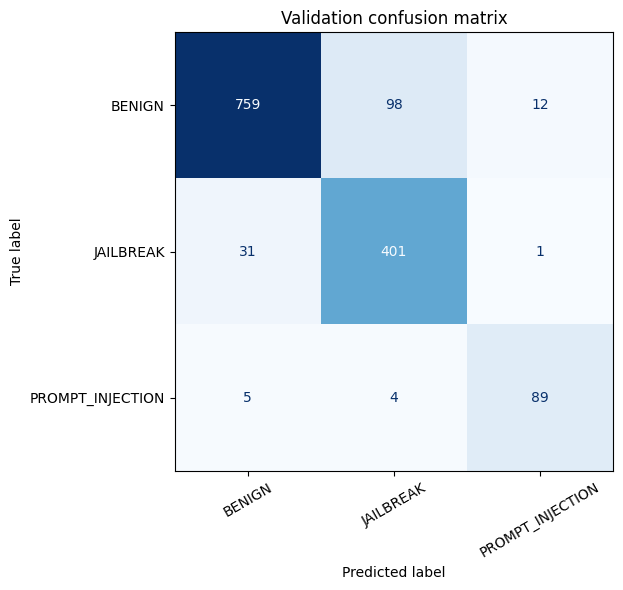

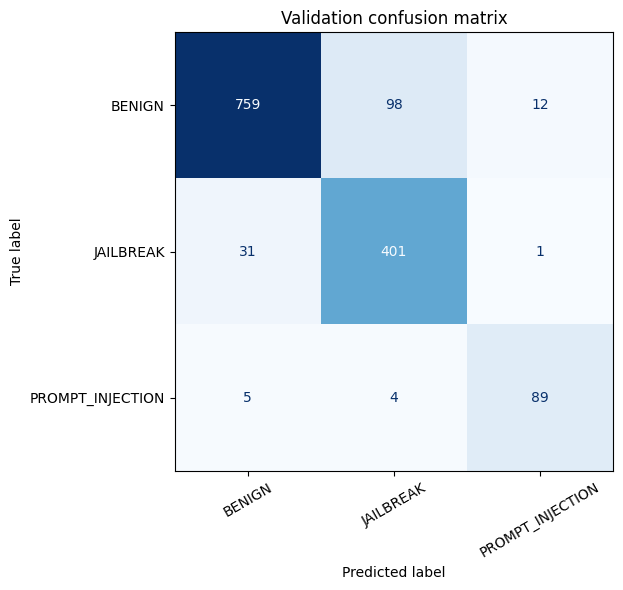

In [14]:
valid_result = trainer.predict(valid_dataset, metric_key_prefix="validation")
valid_logits = valid_result.predictions
if isinstance(valid_logits, tuple):
    valid_logits = valid_logits[0]
if not np.isfinite(valid_logits).all():
    raise ValueError("Validation logits co NaN/Inf; kiem tra training.")
valid_pred = np.argmax(valid_logits, axis=-1)
valid_true = valid_df["label_id"].to_numpy()
report = classification_report(
    valid_true, valid_pred, labels=list(range(len(LABELS))),
    target_names=LABELS, output_dict=True, zero_division=0,
)
report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv(ARTIFACT_DIR / "validation_class_report.csv")

language_rows = []
for language in LANGUAGES:
    mask = valid_df["language"].eq(language).to_numpy()
    if not mask.any():
        continue
    f1_values = f1_score(
        valid_true[mask], valid_pred[mask], labels=list(range(len(LABELS))),
        average=None, zero_division=0,
    )
    row = {"language": language, "rows": int(mask.sum()), "macro_f1": float(f1_values.mean())}
    row.update({f"f1_{label}": float(score) for label, score in zip(LABELS, f1_values)})
    language_rows.append(row)
language_report = pd.DataFrame(language_rows)
display(language_report)
language_report.to_csv(ARTIFACT_DIR / "validation_by_language.csv", index=False)

validation_predictions = valid_df[["id", "language", "label"]].copy()
validation_predictions["predicted_label"] = [ID2LABEL[int(value)] for value in valid_pred]
validation_predictions.to_csv(ARTIFACT_DIR / "validation_predictions.csv", index=False)

matrix = confusion_matrix(valid_true, valid_pred, labels=list(range(len(LABELS))))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(
    ax=ax, values_format="d", cmap="Blues", xticks_rotation=30, colorbar=False,
)
ax.set_title("Validation confusion matrix")
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "validation_confusion_matrix.png", dpi=150)
plt.show()
plt.close(fig)


## 10. Dự đoán test và xuất submission

Dự đoán giữ liên kết với test ID, sau đó sắp theo **sample_submission.csv**. File nộp chỉ có hai cột **id,label** và đúng 6.000 dòng. Nhãn mẫu không ảnh hưởng dự đoán.


In [ ]:
test_result = trainer.predict(test_dataset, metric_key_prefix="test")
test_logits = test_result.predictions
if isinstance(test_logits, tuple):
    test_logits = test_logits[0]
if test_logits.shape != (len(test_df), len(LABELS)) or not np.isfinite(test_logits).all():
    raise ValueError("Test logits sai shape hoac co NaN/Inf.")
test_pred = np.argmax(test_logits, axis=-1)

predictions = pd.DataFrame({
    "id": test_df["id"].to_numpy(),
    "label": [ID2LABEL[int(value)] for value in test_pred],
})
submission = sample_df[["id"]].merge(
    predictions, on="id", how="left", sort=False, validate="one_to_one",
)

def validate_submission(frame, expected_test, template):
    assert list(frame.columns) == ["id", "label"], "Sai cot submission."
    assert len(frame) == len(expected_test) == 6000, "Sai so dong."
    assert frame["id"].is_unique, "ID trung."
    assert frame.notna().all().all(), "Submission co gia tri thieu."
    assert set(frame["id"]) == set(expected_test["id"]), "Thieu/thua ID."
    assert frame["id"].tolist() == template["id"].tolist(), "Sai thu tu sample."
    assert frame["label"].isin(LABELS).all(), "Nhan khong hop le."

validate_submission(submission, test_df, sample_df)
SUBMISSION_PATH = ARTIFACT_DIR / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False, encoding="utf-8")
# Kiem tra ca file tren dia, khong chi DataFrame trong RAM.
saved_submission = pd.read_csv(SUBMISSION_PATH, dtype=str, keep_default_na=False)
validate_submission(saved_submission, test_df, sample_df)

display(saved_submission.head())
display(saved_submission["label"].value_counts().reindex(LABELS, fill_value=0))
print("Submission OK:", SUBMISSION_PATH)
print("SHA256:", hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest())


## 11. Lưu thông tin chạy và đóng gói

ZIP chứa adapter cùng classification heads, tokenizer, label mapping, cấu hình, split ID, báo cáo validation và submission. Base model không được đóng gói lại; khi dùng adapter cần nạp cùng backbone/revision và cấu hình quantization.

Các checkpoint có optimizer để tiếp tục train nằm riêng trong RUN_DIR/checkpoints; ZIP chỉ chứa artifact cuối. Validation metric thuộc model huấn luyện trên train split, không có bước refit toàn bộ 14.000 dòng.


In [ ]:
run_config = {
    "team": "RMIT_SGS_Sigma69_C1",
    "run_id": RUN_ID,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "model_source": MODEL_SOURCE,
    "requested_revision": MODEL_REVISION,
    "resolved_model_revision": RESOLVED_MODEL_REVISION,
    "labels": LABELS,
    "label2id": LABEL2ID,
    "seed": SEED,
    "validation_size": VAL_SIZE,
    "training_rows": len(fit_df),
    "validation_rows": len(valid_df),
    "test_rows": len(test_df),
    "max_length": MAX_LENGTH,
    "long_text_mode": LONG_TEXT_MODE,
    "epochs_requested": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "effective_batch_size": TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS,
    "class_weights": weight_values.tolist(),
    "loss": "inverse_frequency_weighted_cross_entropy_mean_over_samples" if USE_CLASS_WEIGHTS else "cross_entropy",
    "quantization": {
        "load_in_4bit": True, "quant_type": "nf4", "double_quant": True,
        "compute_dtype": str(COMPUTE_DTYPE), "skip_modules": HEAD_MODULES,
    },
    "lora": {
        "rank": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT,
        "target_modules": LORA_TARGETS, "modules_to_save": HEAD_MODULES,
    },
    "gpu": torch.cuda.get_device_name(0),
    "package_versions": PACKAGE_VERSIONS,
    "data_sha256": DATA_HASHES,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_validation_macro_f1": trainer.state.best_metric,
    "submission_sha256": hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest(),
}
(ARTIFACT_DIR / "run_config.json").write_text(
    json.dumps(run_config, indent=2, ensure_ascii=False), encoding="utf-8",
)
(ARTIFACT_DIR / "label_mapping.json").write_text(
    json.dumps({"label2id": LABEL2ID, "id2label": ID2LABEL}, indent=2), encoding="utf-8",
)
(ARTIFACT_DIR / "validation_metrics.json").write_text(
    json.dumps(valid_result.metrics, indent=2), encoding="utf-8",
)
(ARTIFACT_DIR / "training_arguments.json").write_text(
    training_args.to_json_string(), encoding="utf-8",
)
(ARTIFACT_DIR / "training_log.json").write_text(
    json.dumps(trainer.state.log_history, indent=2), encoding="utf-8",
)
(ARTIFACT_DIR / "requirements-used.txt").write_text(
    "\n".join(f"{name}=={release}" for name, release in PACKAGE_VERSIONS.items()) + "\n",
    encoding="utf-8",
)
ARCHIVE_PATH = Path(shutil.make_archive(
    str(RUN_DIR / "rmit_c1_artifacts"), "zip", root_dir=str(ARTIFACT_DIR),
))
print("Artifacts:", ARTIFACT_DIR)
print("ZIP:", ARCHIVE_PATH, f"({ARCHIVE_PATH.stat().st_size / 2**20:.1f} MiB)")


## 12. Tải kết quả

Hai cell dưới tải CSV và ZIP về máy. Nếu trình duyệt chặn tải tự động, tải từ panel **Files** của Colab theo đường dẫn đã in. Kaggle nhận file **submission.csv**, không nhận ZIP adapter làm prediction file.


In [21]:
from pathlib import Path
from shutil import copy2
from IPython.display import FileLink, display

src = Path(SUBMISSION_PATH)
assert src.exists(), f"Không tìm thấy: {src}"

dst = Path("/content/submission.csv")
copy2(src, dst)

print("Đã tạo:", dst, "|", dst.stat().st_size, "bytes")
display(FileLink(str(dst)))

Đã tạo: /content/submission.csv | 100746 bytes


/content/submission.csv

In [19]:
files.download(str(ARCHIVE_PATH))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Tài liệu đối chiếu

- [Đề bài và submission](https://www.kaggle.com/competitions/rmit-hackathon-2026/overview)
- [DistilBERT multilingual](https://huggingface.co/distilbert/distilbert-base-multilingual-cased)
- [PEFT quantization](https://huggingface.co/docs/peft/v0.17.0/en/developer_guides/quantization)
- [PEFT LoRA config](https://huggingface.co/docs/peft/v0.17.0/en/package_reference/lora)
- [Transformers 4-bit quantizer](https://github.com/huggingface/transformers/blob/v4.57.6/src/transformers/quantizers/quantizer_bnb_4bit.py)
- [Trainer loss và gradient accumulation](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer)

Các phiên bản và tham số đã được đối chiếu tài liệu/API. Việc chạy thành công, thời gian huấn luyện và điểm số cần được xác nhận khi bạn thực thi trên Colab.
